# The Diffusion Problem

This notebook introduces the one-dimensional parametric diffusion problem (Section 2.1) that serves as the running example throughout this repository. 
We implement and validate a finite difference solver for the PDE, which serves as the operator that later notebooks will approximate with surrogates.

In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 12, 'figure.figsize': (15, 4)})

import error

%load_ext autoreload
%autoreload 2

## The PDE and the Solution Operator

We consider the parametric diffusion equation

$$-\frac{d}{d\eta}\left(x(\eta)\frac{dy}{d\eta}(\eta)\right) = f(\eta), \qquad \eta \in (0,1),$$

with Dirichlet boundary conditions $y(0) = y_0$ and $y(1) = y_1$.

The coefficient $x : [0,1] \to [x_-, x_+]$, $x_+ \ge x_- > 0$, models a spatially varying material property (e.g. permeability in a porous medium). Given $x$, the **solution operator**

$$\mathcal{G} : x \mapsto y$$

maps the coefficient to the corresponding PDE solution. Throughout this repository we fix homogeneous Dirichlet conditions $y_0 = y_1 = 0$ and constant source term $f \equiv 1$.

For general $x$, the PDE has no closed-form solution, so we approximate it numerically using the **finite difference** (FD) method, which replaces the continuous derivative by difference quotients on a grid.

## Finite Difference Discretisation

Divide $[0,1]$ into $N$ equal intervals with nodes $\eta_j = j/N$ and midpoints $\xi_j = (\eta_j + \eta_{j+1})/2$, $j = 0, \ldots, N-1$.  We seek the $N-1$ interior values $y_j \approx y(\eta_j)$, $j = 1, \ldots, N-1$; the boundary values $y_0$ and $y_N$ are prescribed.

**Step 1: approximate the flux.** At midpoint $\xi_j$, approximate the flux $x\frac{dy}{d\eta}$ by the centred difference

$$\left(x\frac{dy}{d\eta}\right)(\xi_j) \approx x(\xi_j)\frac{y_{j+1} - y_j}{h}, \qquad h = 1/N.$$

**Step 2: discretise the divergence.** At interior node $\eta_j$, $j = 1, \ldots, N-1$, apply a further difference to obtain

$$-\frac{d}{d\eta}\left(x\frac{dy}{d\eta}\right)(\eta_j) \approx -\frac{\left(x\frac{dy}{d\eta}\right)(\xi_j) - \left(x\frac{dy}{d\eta}\right)(\xi_{j-1})}{h}
= -\frac{x(\xi_{j-1})}{h^2}y_{j-1}
+ \frac{x(\xi_{j-1})+x(\xi_j)}{h^2}y_j
- \frac{x(\xi_j)}{h^2}y_{j+1}.$$

**Step 3: assemble and solve.** Moving known boundary values to the right-hand side gives the $(N-1) \times (N-1)$ tridiagonal system

$$\underbrace{\begin{bmatrix}
x_0 + x_1 & -x_1      &            &              \\
-x_1      & x_1 + x_2 & -x_2       &              \\
          & \ddots    & \ddots     & \ddots       \\
          &           & -x_{N-2}   & x_{N-2} + x_{N-1}
\end{bmatrix}}_{A}
\begin{bmatrix} y_1 \\ y_2 \\ \vdots \\ y_{N-1} \end{bmatrix}
=
\underbrace{\begin{bmatrix} f(\eta_1) + x_0 y_0 \\ f(\eta_2) \\ \vdots \\ f(\eta_{N-1}) + x_{N-1} y_N \end{bmatrix}}_{b}$$

where $x_j = x(\xi_j)/h^2$. Since $A$ is symmetric positive definite, this system has a unique solution, which is found efficiently by a direct sparse solver.

In [2]:
#EXPORT

class Grid:

    def __init__(self, N):
        """ N : number of intervals (yields N+1 nodes and N-1 interior nodes) """
        self.nodes_bd  = np.linspace(0, 1, N+1)                        # eta_0, ..., eta_N
        self.nodes     = self.nodes_bd[1:-1]                           # eta_1, ..., eta_{N-1}
        self.midpoints = (self.nodes_bd[:-1] + self.nodes_bd[1:]) / 2  # xi_0, ..., xi_{N-1}
        self.h = 1 / N
        self.N = N

In [3]:
#EXPORT

class Diffusion:
    """
    Solver for the 1D parametric diffusion equation
        -(x(eta) y'(eta))' = f(eta),   eta in (0,1),
    with Dirichlet boundary conditions y(0) = y0, y(1) = y1.
    """

    def __init__(self, *, coefficient = lambda eta: np.ones((len(eta),)),
                          source = lambda eta: np.ones((len(eta),)),
                          y0=0, y1=0):
        self.coefficient = coefficient
        self.source    = source
        self.y_bd      = [y0, y1]

    def __call__(self, grid):
        
        # assemble matrix A
        cv = np.zeros((grid.N+1,))
        cv[:grid.N] = self.coefficient(grid.midpoints) / grid.h**2
        A = sp.sparse.spdiags(
                data = (-cv[1:-1], 
                         cv[:-2] + cv[1:-1], 
                        -cv[[grid.N] + list(range(1, grid.N-1))]),
                diags = [-1, 0, 1])

        # assemble rhs f
        f = self.source(grid.nodes)

        # consider bc
        f[0]  += cv[0] * self.y_bd[0]
        f[-1] += cv[grid.N - 1] * self.y_bd[1]

        # solve Au=f and return u
        return np.concatenate(([self.y_bd[0]], sp.sparse.linalg.spsolve(A.tocsr(), f), [self.y_bd[1]]))

## 1. Validation: Analytical Reference Solution

For constant coefficient $x(\eta) = 1$, constant source $f(\eta) = 1$, and homogeneous Dirichlet conditions $y(0) = y(1) = 0$, the PDE reduces to $-y'' = 1$, which integrates to

$$y(\eta) = \tfrac{1}{2}\eta(1-\eta).$$

We compare the finite difference solution on a coarse grid ($N = 32$) against this exact solution.

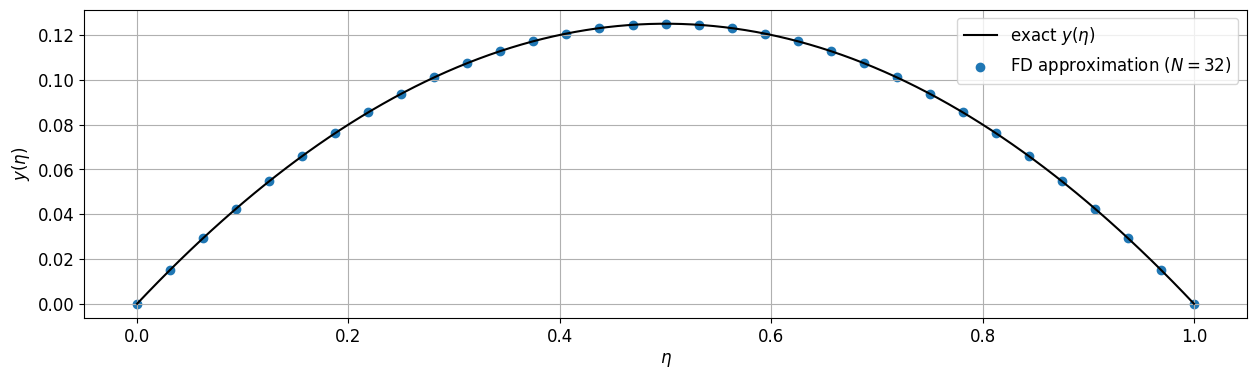

In [4]:
grid = Grid(32)
pde  = Diffusion()

eta = np.linspace(0, 1, 100)
plt.plot(eta, 0.5*eta*(1-eta), 'k', label=r'exact $y(\eta)$')
plt.scatter(grid.nodes_bd, pde(grid), marker='o', label='FD approximation ($N=32$)')
plt.xlabel(r'$\eta$'); plt.ylabel(r'$y(\eta)$'); plt.legend(); plt.grid()
plt.show()

## 2. Non-constant Coefficient

We now use a spatially varying coefficient

$$x(\eta) = 1.1 + \sin(2\pi \eta).$$

Since $\sin(2\pi \eta) \geq -1$, we have $x(\eta) = 1.1 + \sin(2\pi \eta) \geq 0.1 > 0$ everywhere, so the PDE remains well-posed.  The solution no longer has a simple closed form, but can be approximated with the finite difference solver.

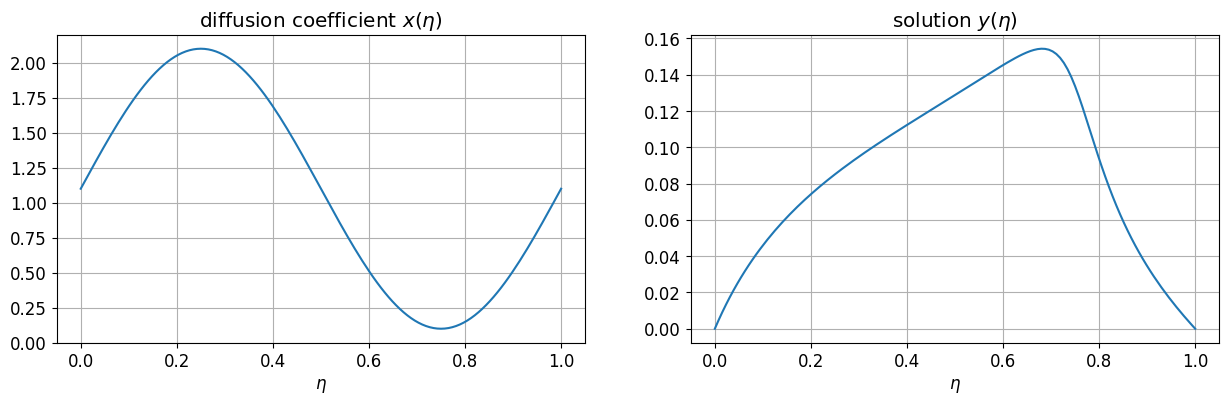

In [5]:
grid = Grid(128)
x = lambda eta: 1.1 + np.sin(2 * np.pi * eta)
pde = Diffusion(coefficient=x)

fig, axs = plt.subplots(1,2)
axs[0].set_title(r'diffusion coefficient $x(\eta)$'); axs[0].plot(grid.nodes_bd, x(grid.nodes_bd))
axs[1].set_title(r'solution $y(\eta)$');           axs[1].plot(grid.nodes_bd, pde(grid))
for ax in axs : ax.grid(); ax.set_xlabel(r'$\eta$')
plt.show()

## 3. Convergence Study

For smooth $x$ and $f$, the finite difference scheme is **second-order accurate**: as the mesh is refined the error satisfies

$$\|y - y_h\|_{L^2} = \mathcal{O}(h^2) = \mathcal{O}(N^{-2}).$$

We verify this empirically using the coefficient $x$ from above.  Since no closed-form solution is available, we use the finest-grid solution ($N = 256$) as a reference and compare coarser solutions after linearly interpolating them to the fine grid.

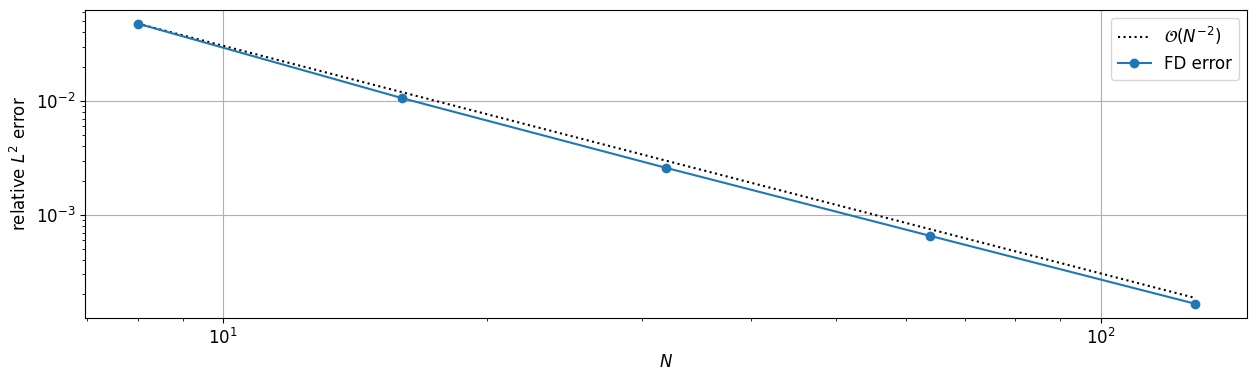

In [6]:
def interpolate(vals, n=1):
    """ Linearly interpolate nodal values onto a grid refined by factor 2^n. """
    for _ in range(n):
        vals = np.concatenate([[vals[i], (vals[i] + vals[i+1])/2] for i in range(len(vals)-1)] + [[vals[-1]]])
    return vals

ns = [2**j for j in range(3, 9)]         # N = 8, 16, 32, 64, 128, 256
sol_fine = pde(Grid(ns[-1]))              # reference solution at N = 256

errs = []
for j, n in enumerate(ns[:-1]):
    sol_coarse = pde(Grid(n))
    sol_ref    = interpolate(sol_coarse, len(ns) - 1 - j)   # interpolate to fine grid
    errs.append(error.l2_rel(sol_fine, sol_ref))

plt.loglog(ns[:-1], np.array(ns[:-1])**(-2.) / ns[0]**(-2.) * errs[0], 'k:', label=r'$\mathcal{O}(N^{-2})$')
plt.loglog(ns[:-1], errs, marker='o', label='FD error')
plt.xlabel(r'$N$'); plt.ylabel(r'relative $L^2$ error'); plt.legend(); plt.grid()
plt.show()